# Biểu đồ và kiểm tra GEO

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Plot Geo G4 Concentration

Nguồn: `src/scripts/plot_geo_g4_concentration.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/plot_geo_g4_concentration.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Compact g4 diversity and top-cell concentration chart from full-history profiles."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT=Path(__file__).resolve().parents[2]
BASE=ROOT/'outputs/eda_figures_moscow'

def main():
    profiles=pd.read_parquet(BASE/'geo_all_history_customer_profiles.parquet')
    q=profiles[profiles.level.eq(4)]
    n_all=pd.read_parquet(ROOT/'outputs/full_population_temporal_eda_20261118/labels_any.parquet',columns=['client_id']).client_id.nunique()
    assert len(q)==q.client_id.nunique() and n_all>=len(q)
    values=q.unique_cells.to_numpy()
    edges=np.arange(.5,100.6,5)
    counts,_=np.histogram(values,bins=edges)
    overflow=int((values>100).sum())
    share=counts/len(q)
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=(11,4.7),gridspec_kw={'width_ratios':[1.25,1]})
    bars=ax1.bar((edges[:-1]+edges[1:])/2,share,width=np.diff(edges)*.92,color='#75a8ef',edgecolor='white',linewidth=.5)
    ax1.bar(115,overflow/len(q),width=5,color='#4773aa')
    ax1.set_xticks([1,20,40,60,80,100,115],['1','20','40','60','80','100','>100'])
    ax1.set_xlim(.5,122);ax1.set_xlabel('Số ô geohash_4 khác nhau / khách')
    ax1.set_ylabel('% khách có GEO theo số ô');ax1.yaxis.set_major_formatter(PercentFormatter(1))
    event_axis=ax1.twiny()
    cdf_axis=event_axis.twinx()
    event_axis.set_xlim(0,6000)
    event_axis.set_xlabel('Số sự kiện GEO / khách',color='#d43d3d')
    event_axis.tick_params(axis='x',colors='#d43d3d')
    event_axis.spines['top'].set_color('#d43d3d')
    cdf_axis.set_xlim(0,6000);cdf_axis.set_ylim(0,1)
    event_grid=np.arange(0,6001,100)
    event_sorted=np.sort(q.events.to_numpy())
    cumulative=np.searchsorted(event_sorted,event_grid,side='right')/len(q)
    line,=cdf_axis.plot(event_grid,cumulative,color='#d43d3d',linewidth=2)
    cdf_axis.set_ylabel('% khách có ≤ số sự kiện',color='#d43d3d')
    cdf_axis.yaxis.set_major_formatter(PercentFormatter(1))
    cdf_axis.tick_params(axis='y',colors='#d43d3d')
    ax1.set_title('Đa dạng ô g4',weight='bold');ax1.grid(axis='y',alpha=.2)
    fig.legend([bars,line],['Phân phối số ô g4','Tích lũy theo số sự kiện GEO'],
               loc='lower left',bbox_to_anchor=(.1,.19),ncol=2,frameon=False,fontsize=8)
    for x,threshold in [(.1,20),(.38,40)]:
        pct=(q.events<threshold).mean()
        fig.text(x,.115,f'{pct:.1%} khách có < {threshold} sự kiện GEO',fontsize=11,weight='bold',
                 color='#a92e2e',bbox=dict(facecolor='#fff1f0',edgecolor='#e9b4b1',boxstyle='round,pad=.5'))
    ax1.text(.98,.50,f'Trung vị: {q.unique_cells.median():.0f} ô\nTrung bình: {q.unique_cells.mean():.1f} ô',
             transform=ax1.transAxes,ha='right',va='center',fontsize=9)
    top=q.top_share.mean()
    ax2.pie([top,1-top],startangle=90,counterclock=False,colors=['#3b8ce8','#dbe5f5'],
            wedgeprops={'width':.28,'edgecolor':'white'})
    ax2.text(0,0,f'{top:.1%}',ha='center',va='center',fontsize=18,weight='bold')
    ax2.set_title('Tỷ lệ ở ô chính g4',weight='bold')
    ax2.legend(['Ô nhiều sự kiện nhất','Các ô còn lại'],loc='center left',bbox_to_anchor=(.95,.5),frameon=False,fontsize=9)
    fig.suptitle('GEO: tập trung và đa dạng theo ô geohash_4',weight='bold',fontsize=15)
    fig.text(.02,.02,f'Toàn lịch sử GEO · {len(q):,}/{n_all:,} khách có log; {n_all-len(q):,} khách không GEO ở ngoài hai phép tính. '
             f'Đường đỏ: ≤ mốc sự kiện, đến 6.000; {int((q.events>6000).sum()):,} khách vượt mốc vẫn thuộc mẫu số. '
             f'Vòng tròn: tỷ trọng ô chính trung bình theo khách.',fontsize=8)
    fig.subplots_adjust(left=.08,right=.85,bottom=.32,top=.76,wspace=.45)
    fig.savefig(BASE/'geo_g4_diversity_top1_compact.png',dpi=180,bbox_inches='tight')
    fig.savefig(BASE/'geo_g4_diversity_top1_compact.svg',bbox_inches='tight')
    print(f'customers={len(q)} no_geo={n_all-len(q)} mean_top1={top:.4f}')

if __name__=='__main__':main()

customers=72573 no_geo=27651 mean_top1=0.7064


### Kết quả: `src/scripts/plot_geo_g4_concentration.py`

**outputs/eda_figures_moscow/geo_g4_diversity_top1_compact.png**

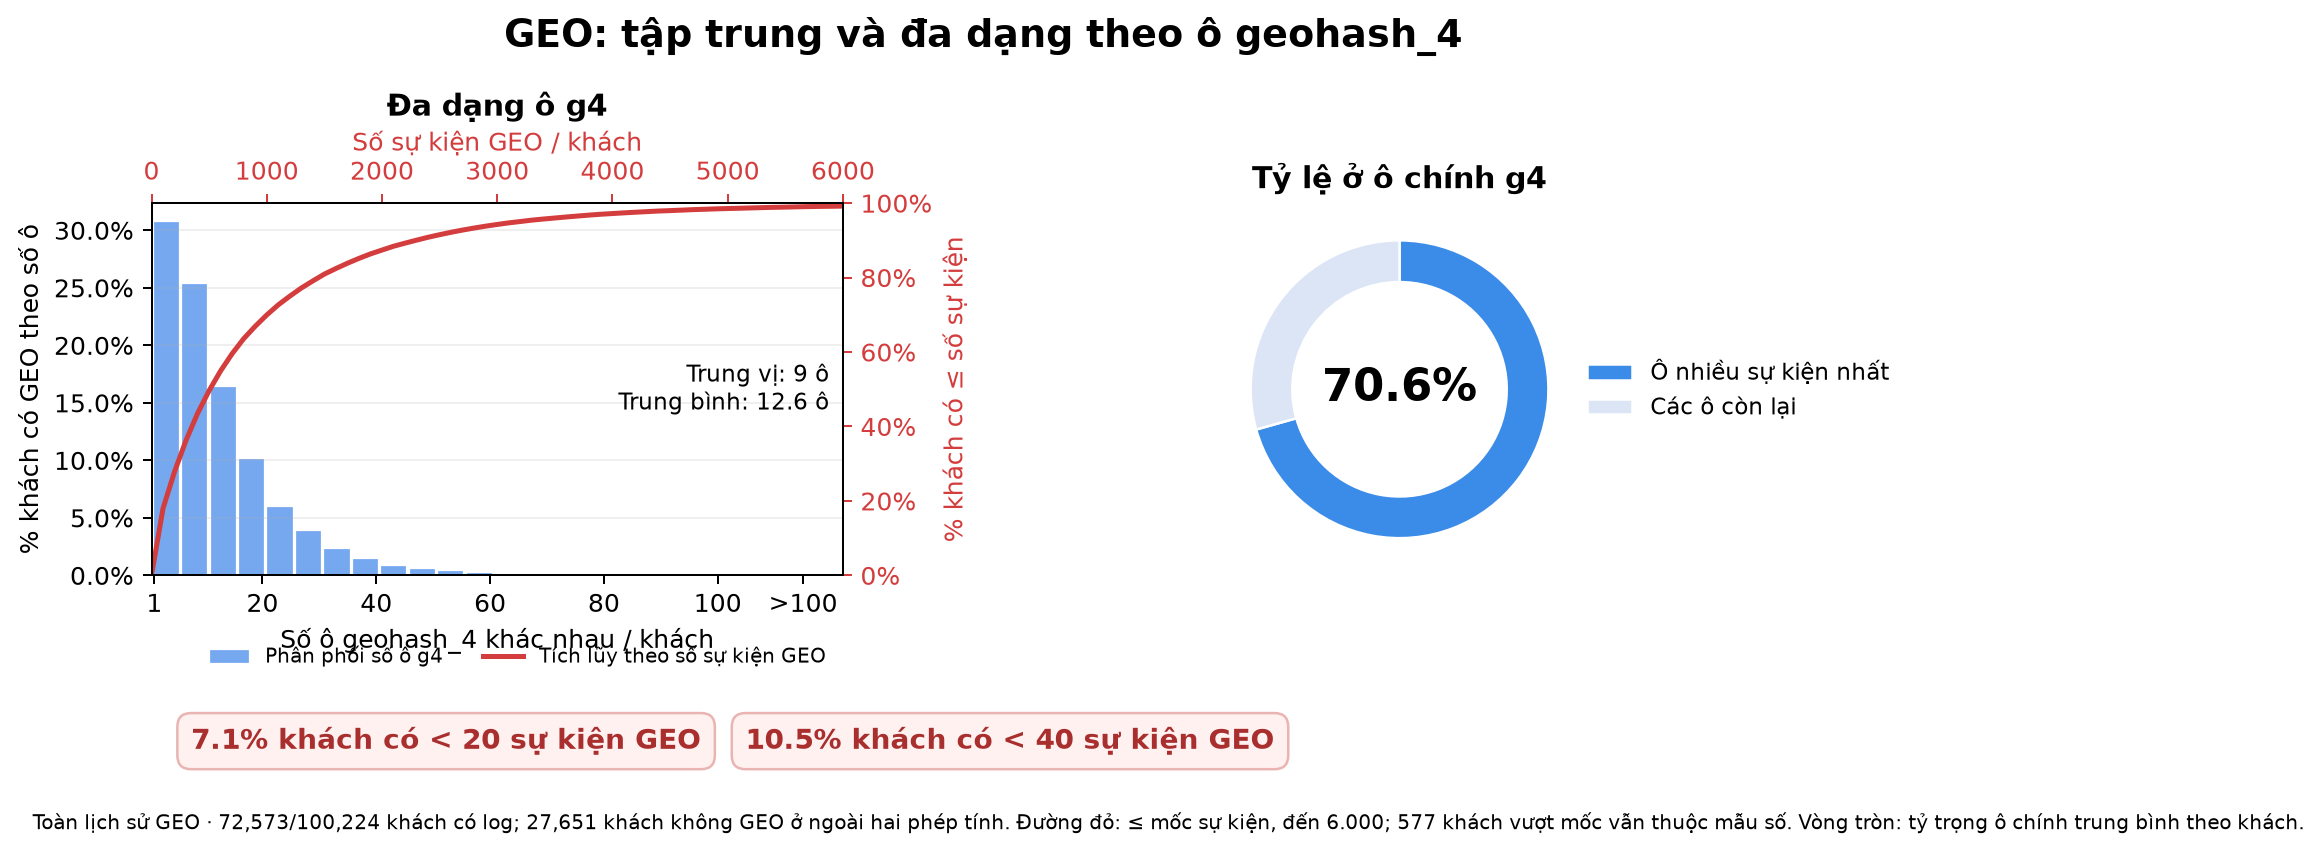

In [4]:
show_generated_results(__eda_started_ns, 'src/scripts/plot_geo_g4_concentration.py')

## Plot Geo Purchase Event Study

Nguồn: `src/scripts/plot_geo_purchase_event_study.py`. Chạy các ô của phần này theo thứ tự.

In [5]:
__file__ = str(ROOT / 'src/scripts/plot_geo_purchase_event_study.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [6]:
"""Plot full-population monthly GEO and DIALOG activity around label months."""
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path(__file__).resolve().parents[2]
BASE = ROOT / 'outputs/full_population_temporal_eda_20261118'
def plot(source):
    d = pd.read_csv(BASE / 'before_after_monthly_rates.csv', parse_dates=['target_month'])
    d = d[d.source.eq(source)].copy()
    assert d.target_month.nunique() >= 12
    assert (d.observed_customers + d.unavailable_customers == d.total_customers).all()
    assert d.groupby(['target_month', 'lag']).total_customers.sum().eq(100224).all()
    for y, title, name in [(1, 'Nhóm có mua trong tháng mốc', 'geo_event_study_buyers'),
                           (0, 'Nhóm không mua trong tháng mốc', 'geo_event_study_nonbuyers')]:
        fig, ax = plt.subplots(figsize=(14, 4.8))
        q = d[d.purchase.eq(y)]
        for lag, color, label in [(-1, '#2875b9', 'Tháng trước mốc mua'),
                                  (1, '#db6b28', 'Tháng sau mốc mua')]:
            z = q[q.lag.eq(lag)].sort_values('target_month')
            ax.plot(z.target_month, z.rate, 'o-', color=color, label=label, linewidth=2)
            for row in z.itertuples():
                if row.unavailable_customers:
                    ax.annotate('chưa quan sát', (row.target_month, .02), rotation=90,
                                ha='center', va='bottom', fontsize=7, color=color)
        ax.set_title(title, loc='left', weight='bold')
        ax.set_ylabel(f'Tỷ lệ khách có ≥1 sự kiện {source.upper()}')
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(alpha=.2)
        ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0),
                  borderaxespad=0, fontsize=9, frameon=False)
        paired = q.pivot(index='target_month', columns='lag', values='rate').dropna(subset=[-1, 1])
        summary = []
        for lag, label in [(-1, 'Tháng trước'), (1, 'Tháng sau')]:
            rates = paired[lag]
            summary.append(f'{label} (n={len(rates)} tháng)\n'
                           f'  Trung bình: {rates.mean():.1%}\n'
                           f'  Trung vị:    {rates.median():.1%}')
        ax.text(1.02, .68, 'Cùng tháng mốc quan sát đủ hai phía\n\n' + '\n\n'.join(summary), transform=ax.transAxes,
                ha='left', va='top', fontsize=10, linespacing=1.5,
                bbox=dict(facecolor='#f4f7fb', edgecolor='#dbe4ee', boxstyle='round,pad=.6'))
        ax.set_xticks(sorted(d.target_month.unique()))
        ax.set_xticklabels([x.strftime('%m/%Y') for x in sorted(d.target_month.unique())], rotation=40)
        ax.set_xlabel('Tháng nhãn làm mốc')
        fig.suptitle(f'{source.upper()} quanh tháng mua | nhãn 02/2022–01/2023', weight='bold')
        fig.text(.01, .01, f'Mẫu số: khách thuộc nhóm có tháng {source.upper()} quan sát được; không có sự kiện vẫn được tính. '
                 f'{source.upper()} giả định UTC → Moscow. Mua lặp được giữ; không suy nhân quả.', fontsize=8)
        fig.subplots_adjust(left=.08, right=.72, bottom=.22, top=.82)
        path = BASE / (name.replace('geo_', f'{source}_') + '.png')
        fig.savefig(path, dpi=170, bbox_inches='tight')
        fig.savefig(path.with_suffix('.svg'), bbox_inches='tight')
        plt.close(fig)
        print(path.name)

if __name__ == '__main__':
    for source in ('geo', 'dialog'):
        plot(source)

geo_event_study_buyers.png


geo_event_study_nonbuyers.png


dialog_event_study_buyers.png


dialog_event_study_nonbuyers.png


### Kết quả: `src/scripts/plot_geo_purchase_event_study.py`

**outputs/full_population_temporal_eda_20261118/dialog_event_study_buyers.png**

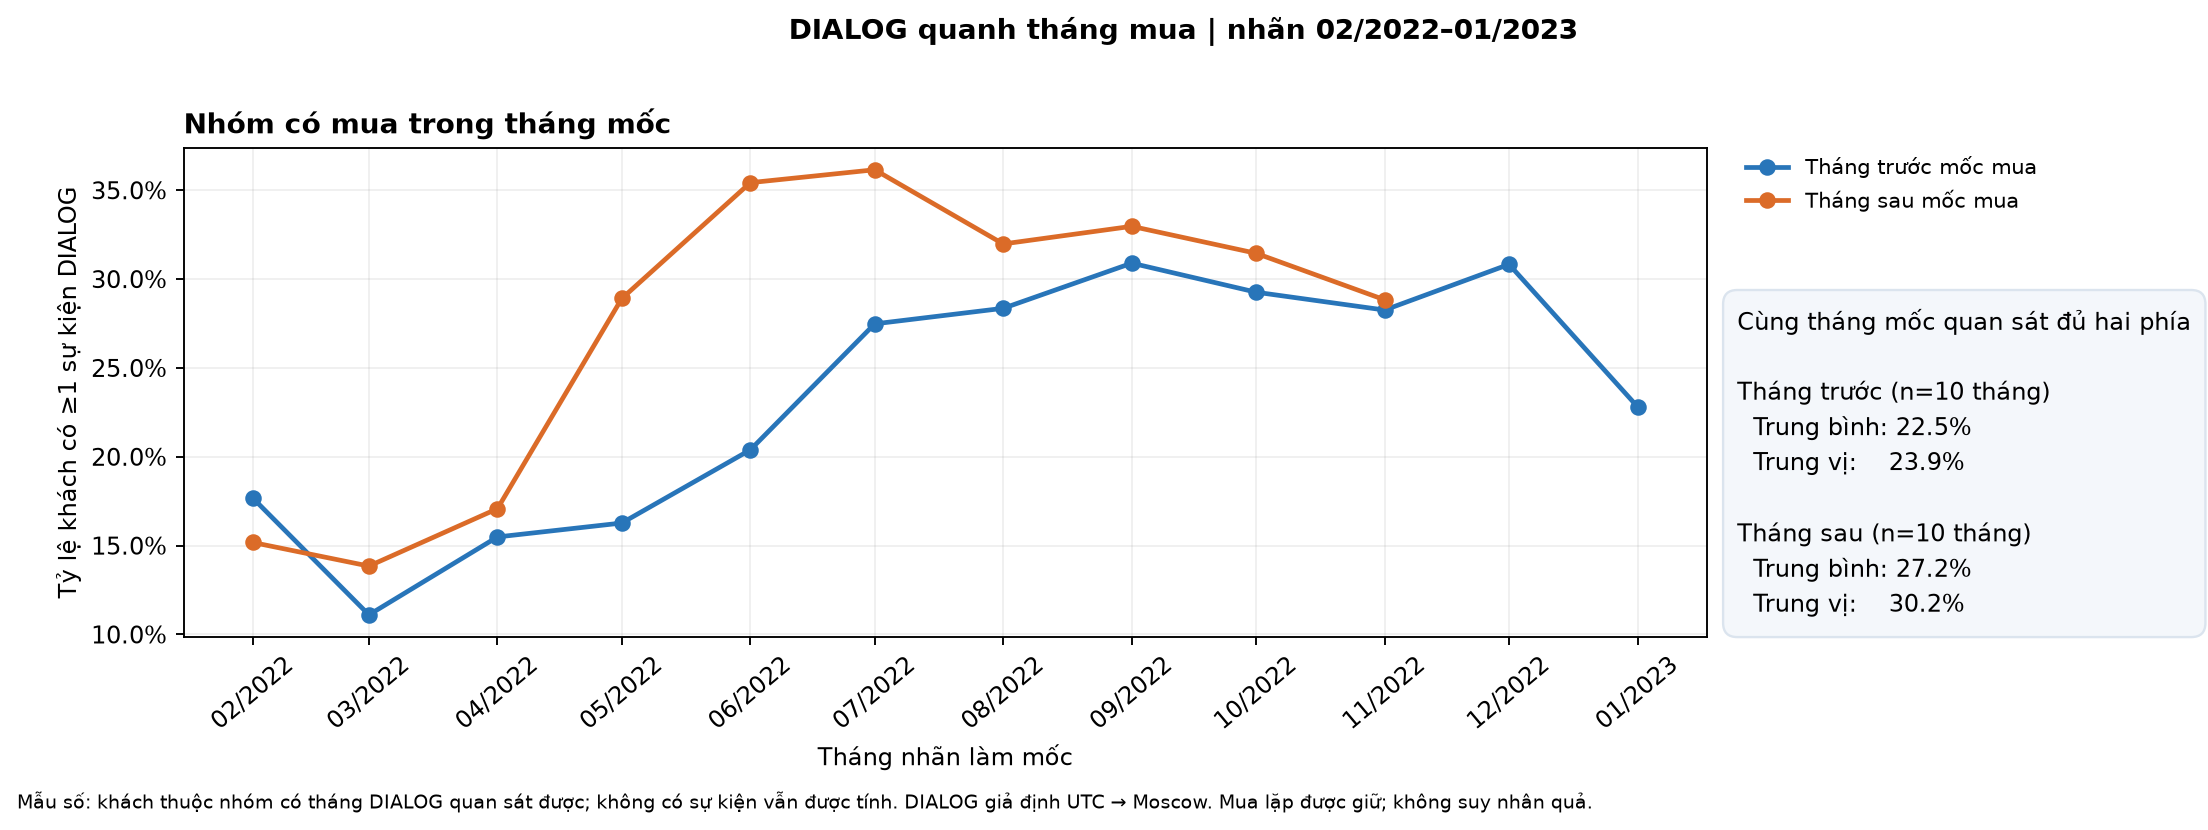

**outputs/full_population_temporal_eda_20261118/dialog_event_study_nonbuyers.png**

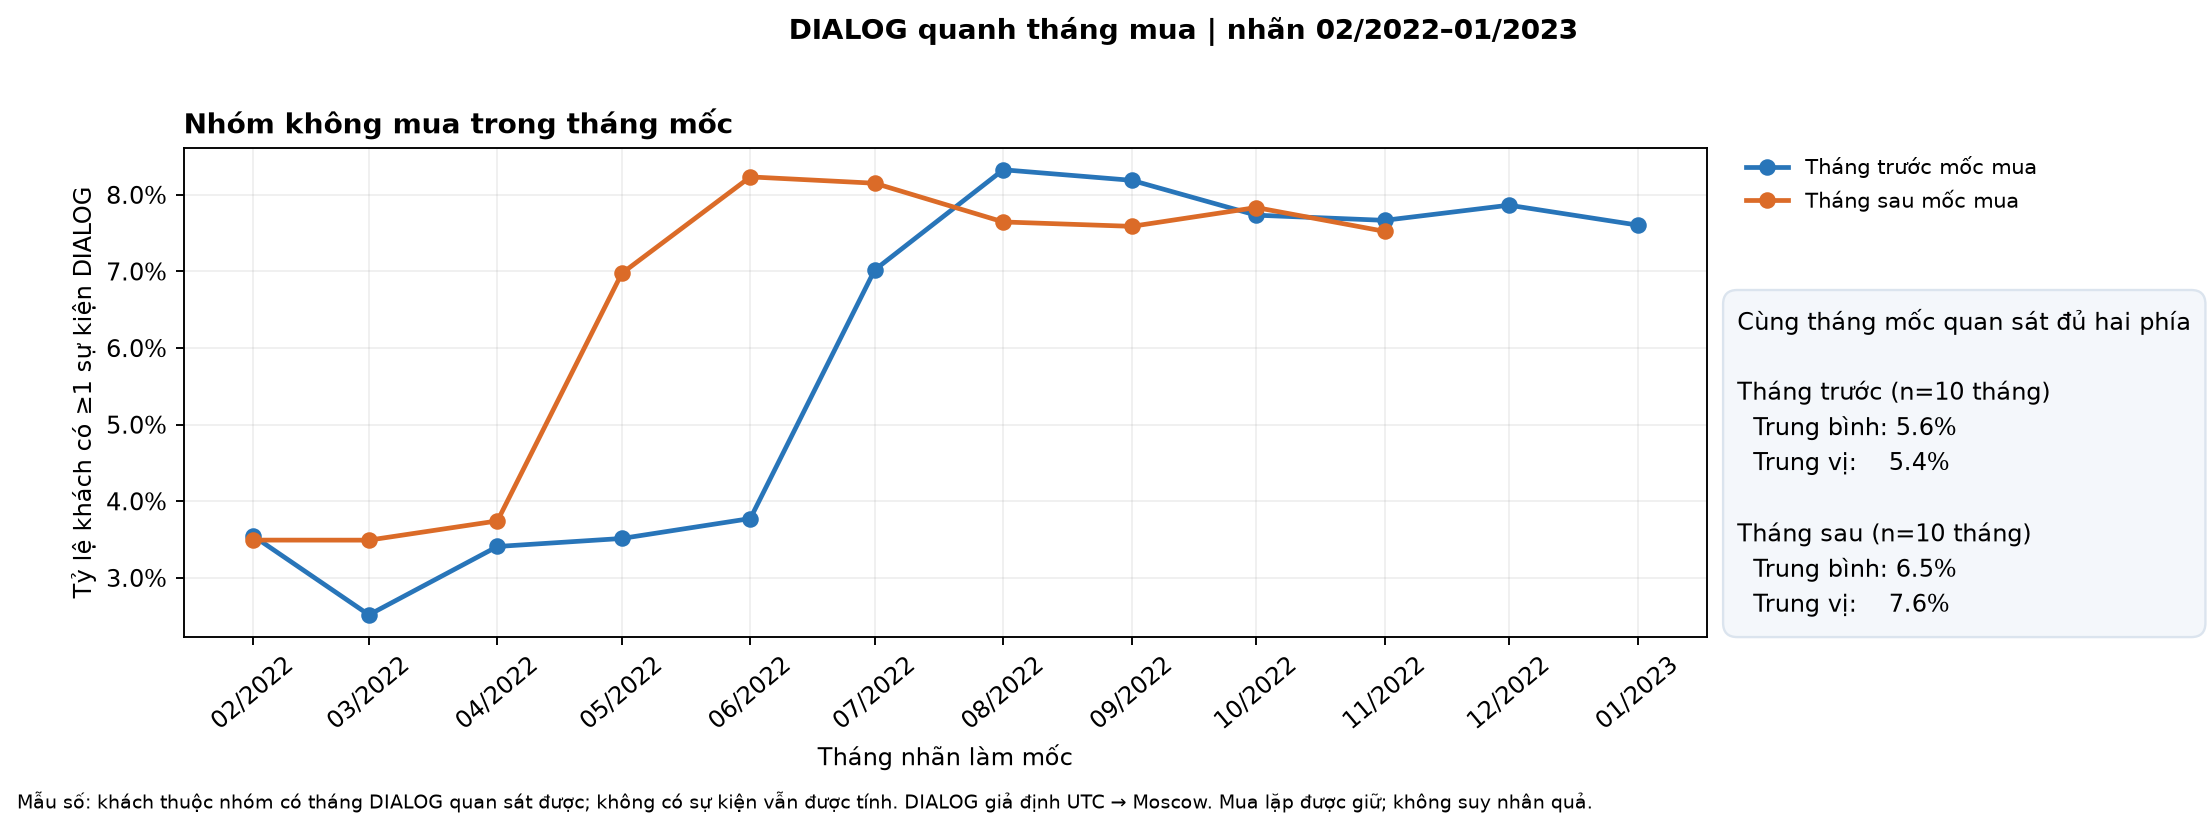

**outputs/full_population_temporal_eda_20261118/geo_event_study_buyers.png**

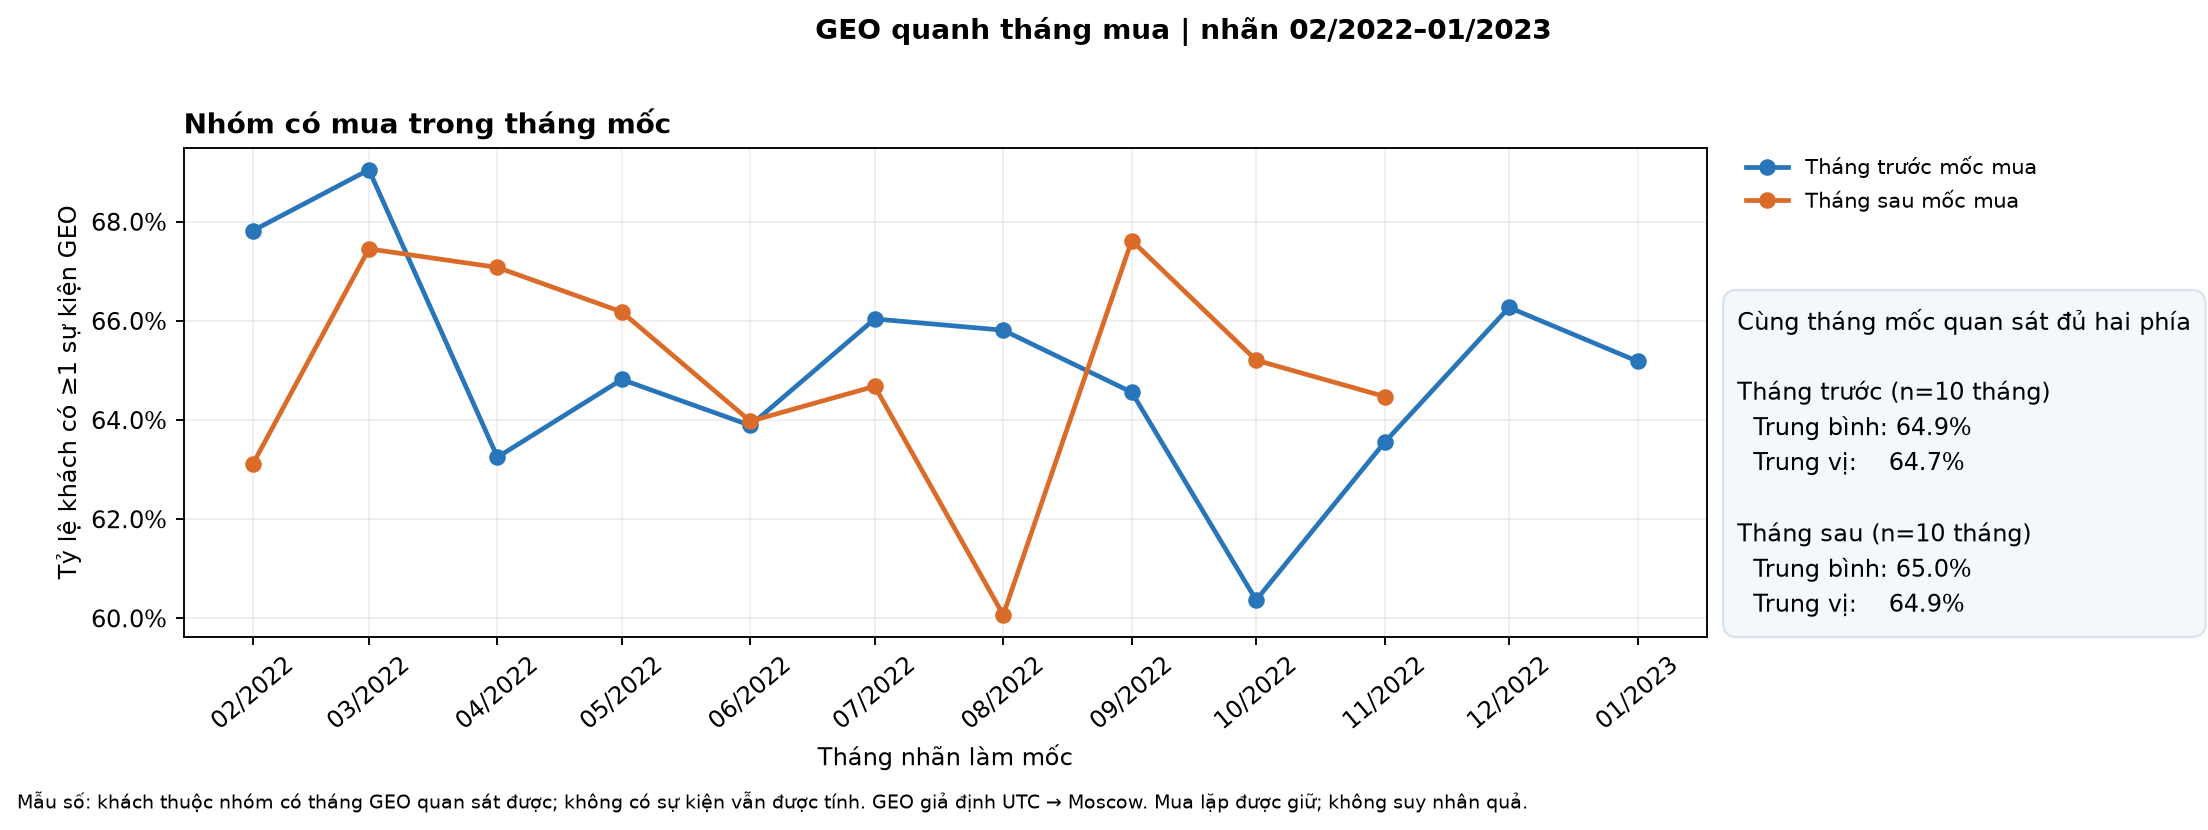

**outputs/full_population_temporal_eda_20261118/geo_event_study_nonbuyers.png**

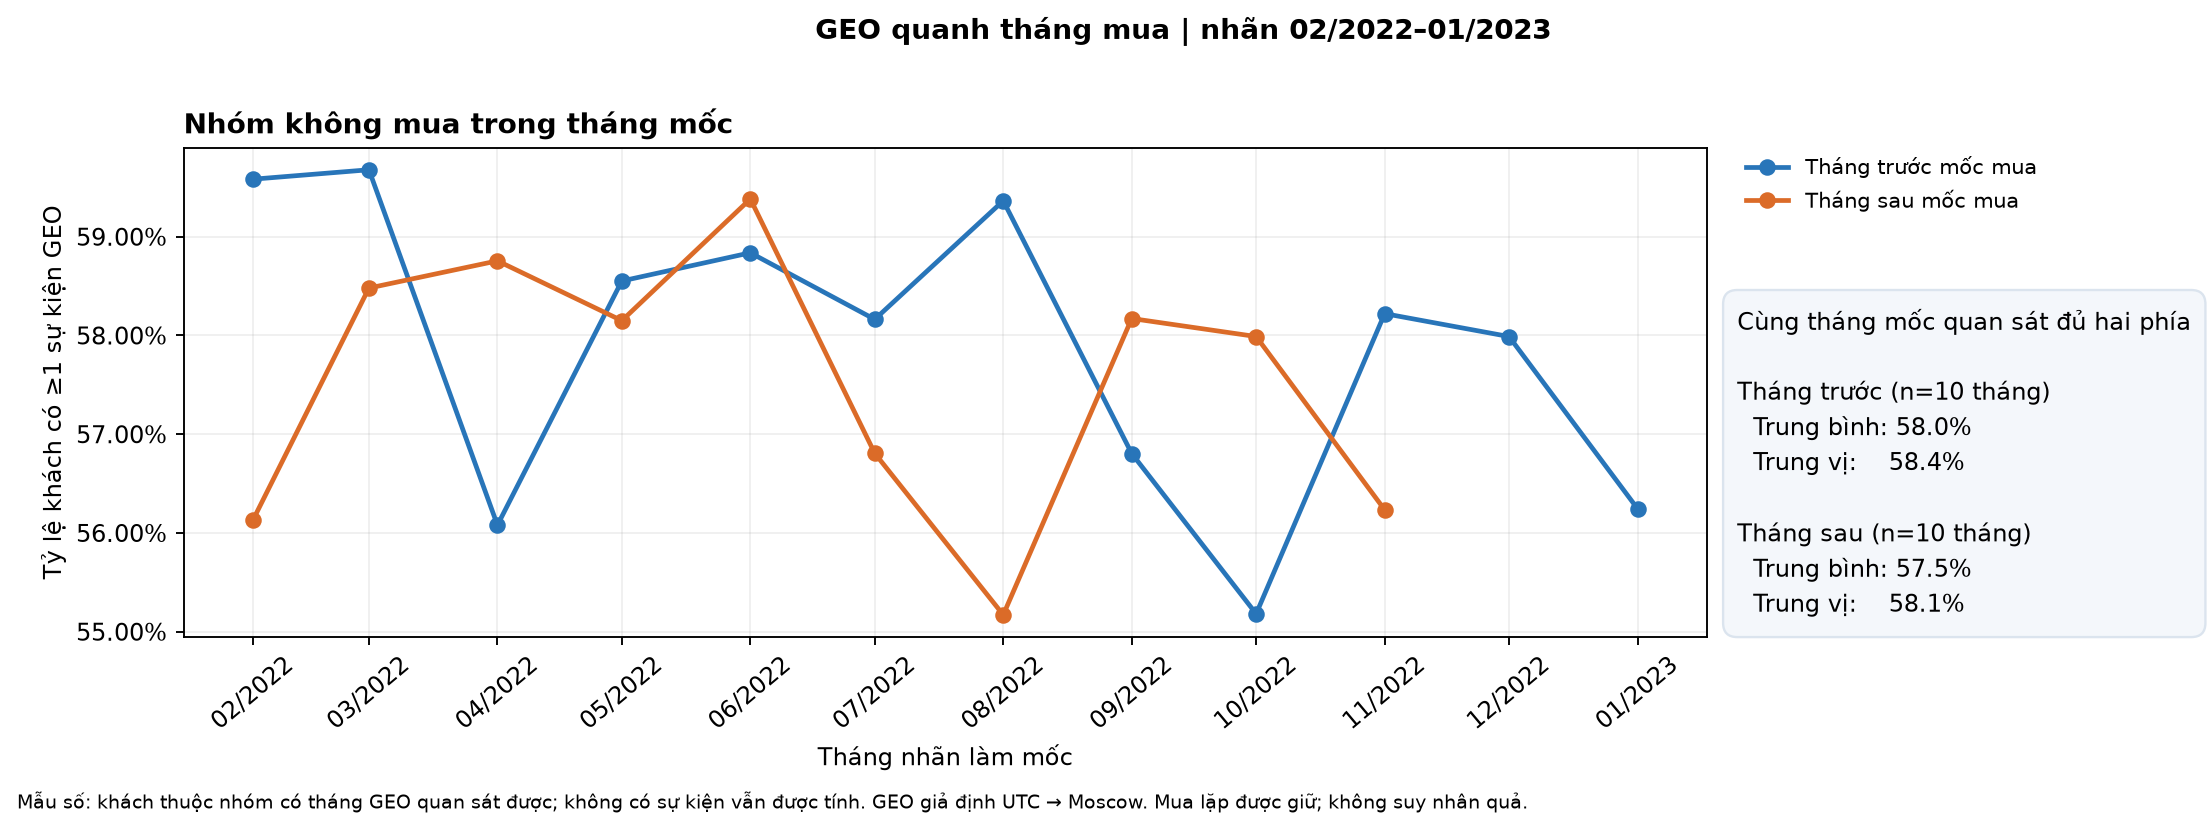

In [7]:
show_generated_results(__eda_started_ns, 'src/scripts/plot_geo_purchase_event_study.py')

## Extend Eda Geo Population

Nguồn: `src/scripts/extend_eda_geo_population.py`. Chạy các ô của phần này theo thứ tự.

In [8]:
__file__ = str(ROOT / 'src/scripts/extend_eda_geo_population.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [9]:
"""All-history categorical GEO profiles, IDF, sparse graph and SVD.

Retrospective source description only; not a past-cutoff feature table.
"""
import json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.sparse import coo_matrix, bmat
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.decomposition import TruncatedSVD
from complete_eda_figures_moscow import ROOT, OUT, BASE, publish, INDEX


def main():
    ids=np.sort(pd.read_parquet(BASE/'labels_any.parquet').client_id.unique())
    c=duckdb.connect();c.execute("SET memory_limit='3GB'");c.execute('SET threads=2')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp_geo'")
    path=(ROOT/'data/MBD-mini/detail/geo/**/*.parquet').as_posix()
    profiles=[]; edges=None
    for level in [4,5,6]:
        print('GEO population level',level,flush=True)
        cache=OUT/f'geo_g{level}_customer_cells.parquet'
        if not cache.exists():
            c.execute(f"COPY (SELECT client_id,geohash_{level} cell,count(*) events FROM read_parquet('{path}') GROUP BY 1,2) TO '{cache.as_posix()}' (FORMAT PARQUET)")
        profile=c.execute(f"""WITH cells AS (SELECT *,sum(events) OVER(PARTITION BY client_id) total FROM read_parquet('{cache.as_posix()}'))
            SELECT client_id,{level} level,max(total) events,count(*) unique_cells,
              max(events)::DOUBLE/max(total) top_share,
              -sum((events::DOUBLE/total)*ln(events::DOUBLE/total)) entropy,
              sum(pow(events::DOUBLE/total,2)) hhi
              FROM cells GROUP BY 1""").df()
        assert int(profile.events.sum())==66295724
        profiles.append(profile)
        if level==4: edges=c.execute(f"SELECT * FROM read_parquet('{cache.as_posix()}')").df()
    c.close()
    p=pd.concat(profiles,ignore_index=True)
    p.to_parquet(OUT/'geo_all_history_customer_profiles.parquet',index=False)
    fig,axes=plt.subplots(3,3,figsize=(13,11))
    for row,level in enumerate([4,5,6]):
        q=p[p.level==level]
        axes[row,0].hist(q.top_share,bins=40);axes[row,0].set_xlabel(f'g{level}: top-1 share')
        axes[row,1].hist(q.entropy,bins=40);axes[row,1].set_xlabel(f'g{level}: entropy, nats')
        axes[row,2].hist2d(np.log1p(q.events),np.log1p(q.unique_cells),bins=50,norm=LogNorm())
        axes[row,2].set_xlabel('log1p số sự kiện');axes[row,2].set_ylabel('log1p số ô')
    summary=p.groupby('level').agg(customers=('client_id','size'),median_cells=('unique_cells','median'),median_entropy=('entropy','median'),median_hhi=('hhi','median'),median_topshare=('top_share','median')).reset_index()
    summary['no_geo_customers']=len(ids)-summary.customers
    publish('geo_concentration_all_levels',fig,summary,'GEO: đa dạng và tập trung ở cả ba cấp',
        'Toàn bộ 66.295.724 sự kiện, nhóm khách–ô ở từng cấp; p=count ô/tổng sự kiện khách. '
        'Entropy=−sum(p ln p), HHI=sum(p²). Histogram chỉ khách có GEO; CSV ghi rõ khách không GEO, không gán entropy=0 cho họ. '
        'Bảng cá thể đầy đủ có trong geo_all_history_customer_profiles.parquet.',
        'So tính tập trung giữa cấp mã và liên hệ cơ học giữa số sự kiện với số ô.',
        '; '.join(f'g{r.level}: median số ô={r.median_cells:.0f}, top-share={r.median_topshare:.3f}, HHI={r.median_hhi:.3f}' for r in summary.itertuples()),
        'Toàn lịch sử nguồn dùng để mô tả, không dùng như feature trước mua. Quan hệ count–số ô không chứng minh di chuyển. '
        'Các histogram không gồm khách chưa có GEO; số đó được ghi rõ ở CSV.')
    cells=np.sort(edges.cell.unique());ci=pd.Index(ids).get_indexer(edges.client_id);gi=pd.Index(cells).get_indexer(edges.cell)
    mat=coo_matrix((edges.events.to_numpy(float),(ci,gi)),shape=(len(ids),len(cells))).tocsr()
    degree=np.asarray((mat>0).sum(axis=1)).ravel()
    cell_degree=np.asarray((mat>0).sum(axis=0)).ravel()
    idf=np.log((len(ids)+1)/(cell_degree+1))+1
    total=np.asarray(mat.sum(axis=1)).ravel()
    mean_idf=np.divide(mat@idf,total,out=np.full(len(ids),np.nan),where=total>0)
    g=bmat([[None,(mat>0).astype(np.int8)],[(mat.T>0).astype(np.int8),None]],format='csr')
    nc,component=connected_components(g,directed=False)
    counts=np.bincount(component); customers_component=np.bincount(component[:len(ids)],minlength=nc)
    out=pd.DataFrame({'client_id':ids,'g4_degree':degree,'event_weighted_idf':mean_idf,
                      'component':component[:len(ids)],'component_nodes':counts[component[:len(ids)]],
                      'component_customers':customers_component[component[:len(ids)]]})
    out.to_parquet(OUT/'geo_g4_graph_idf_customers.parquet',index=False)
    fig,axes=plt.subplots(1,3,figsize=(14,4.5))
    axes[0].hist(mean_idf[np.isfinite(mean_idf)],bins=50);axes[0].set_xlabel('IDF trung bình trọng số sự kiện')
    axes[1].hist(np.log1p(degree),bins=50);axes[1].set_xlabel('log1p bậc g4 / toàn bộ khách')
    axes[2].hist(np.log1p(customers_component[customers_component>0]),bins=50,log=True)
    axes[2].set_xlabel('log1p số khách / thành phần');axes[2].set_ylabel('Số thành phần, log')
    comps=pd.DataFrame({'component':np.arange(nc),'nodes':counts,'customers':customers_component})
    publish('geo_g4_idf_graph',fig,comps,'GEO g4: độ hiếm và thành phần đồ thị khách–ô',
        'Đồ thị hai phía có mọi khách và mọi g4; cạnh khi khách từng có sự kiện trong ô. '
        'IDF=ln((100224+1)/(số khách ô+1))+1, trung bình theo tần suất sự kiện. '
        'Connected components bằng scipy sparse; khách không GEO là nút cô lập.',
        'Mô tả độ hiếm ô và mức kết nối khách qua các ô dùng chung, không suy quan hệ doanh nghiệp.',
        f'{nc:,} thành phần, {int((degree==0).sum()):,} khách cô lập; thành phần nhiều khách nhất có {int(customers_component.max()):,} khách.',
        'Ô phổ biến có thể nối phần lớn khách; cùng thành phần không chứng minh cùng địa điểm hay tập đoàn. '
        'Chưa tính nút khớp/cặp hiếm; IDF toàn kỳ không phải thống kê có sẵn ở cutoff quá khứ.')
    tfidf=TfidfTransformer().fit_transform(mat)
    svd=TruncatedSVD(n_components=32,random_state=42)
    z=svd.fit_transform(tfidf)
    np.savez_compressed(OUT/'geo_g4_bag_svd32.npz',client_ids=ids.astype(str),embedding=z.astype(np.float32))
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    active=degree>0
    axes[0].hist2d(z[active,0],z[active,1],bins=60,norm=LogNorm());axes[0].set_xlabel('SVD1');axes[0].set_ylabel('SVD2')
    axes[1].plot(np.arange(1,33),np.cumsum(svd.explained_variance_ratio_)*100);axes[1].set_xlabel('Số chiều');axes[1].set_ylabel('% phương sai tích lũy')
    var=pd.DataFrame({'dimension':np.arange(1,33),'variance_ratio':svd.explained_variance_ratio_})
    publish('geo_g4_bag_svd',fig,var,'GEO g4: biểu diễn bag-of-cells TF-IDF và SVD',
        'Ma trận thưa toàn bộ khách × g4, trọng số số sự kiện; TF-IDF mặc định sklearn (smooth IDF, L2), SVD32 seed42. '
        'Hình mật độ giữ mọi khách có GEO; khách không GEO có vector zero và mask qua bậc đồ thị.',
        'Quan sát cấu trúc đồng xuất hiện ô giữa khách; không coi trục SVD là tọa độ địa lý.',
        f'32 chiều giữ {svd.explained_variance_ratio_.sum()*100:.2f}% phương sai theo định nghĩa TruncatedSVD; '
        f'{int(active.sum()):,} khách có GEO và {int((~active).sum()):,} khách vector zero vì không nguồn.',
        'Fit hồi cứu toàn kỳ, chưa đánh giá ổn định theo thời gian hoặc quan hệ nhãn. Không thay thế cell2vec chuỗi.')
    old=pd.read_csv(OUT/'figure_index.csv');idx=pd.concat([old,pd.DataFrame(INDEX)]).drop_duplicates('figure',keep='last');idx.to_csv(OUT/'figure_index.csv',index=False)
    status=json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'))
    status['done']+=['geo_all_level_entropy_hhi','geo_g4_idf_sparse_components','geo_g4_bag_tfidf_svd32']
    status['figures']=len(idx)
    (OUT/'execution_status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')


if __name__=='__main__':main()

GEO population level 4


GEO population level 5


GEO population level 6


Saved geo_concentration_all_levels


Saved geo_g4_idf_graph


Saved geo_g4_bag_svd


### Kết quả: `src/scripts/extend_eda_geo_population.py`

**outputs/eda_figures_moscow/geo_concentration_all_levels.png**

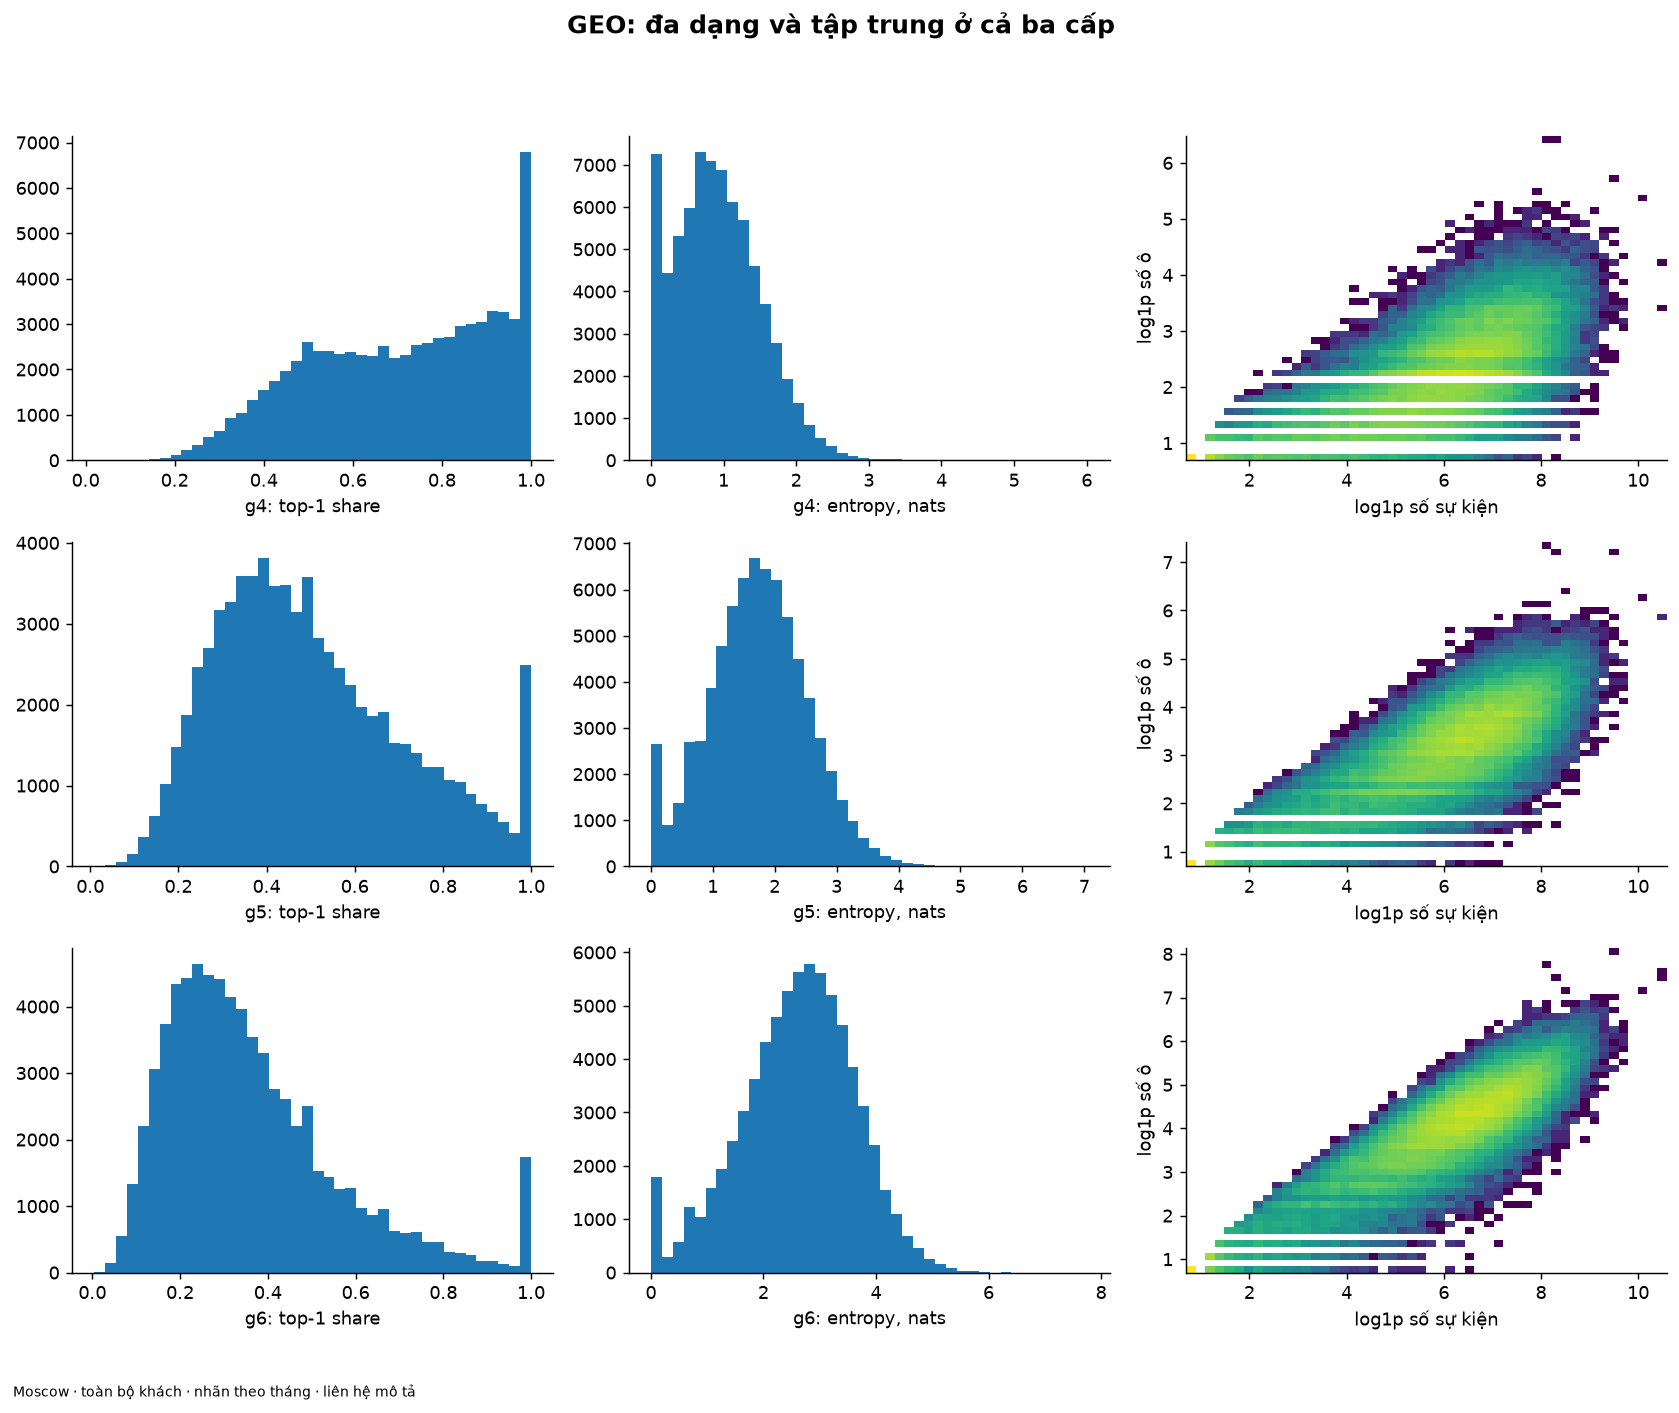

**outputs/eda_figures_moscow/geo_g4_bag_svd.png**

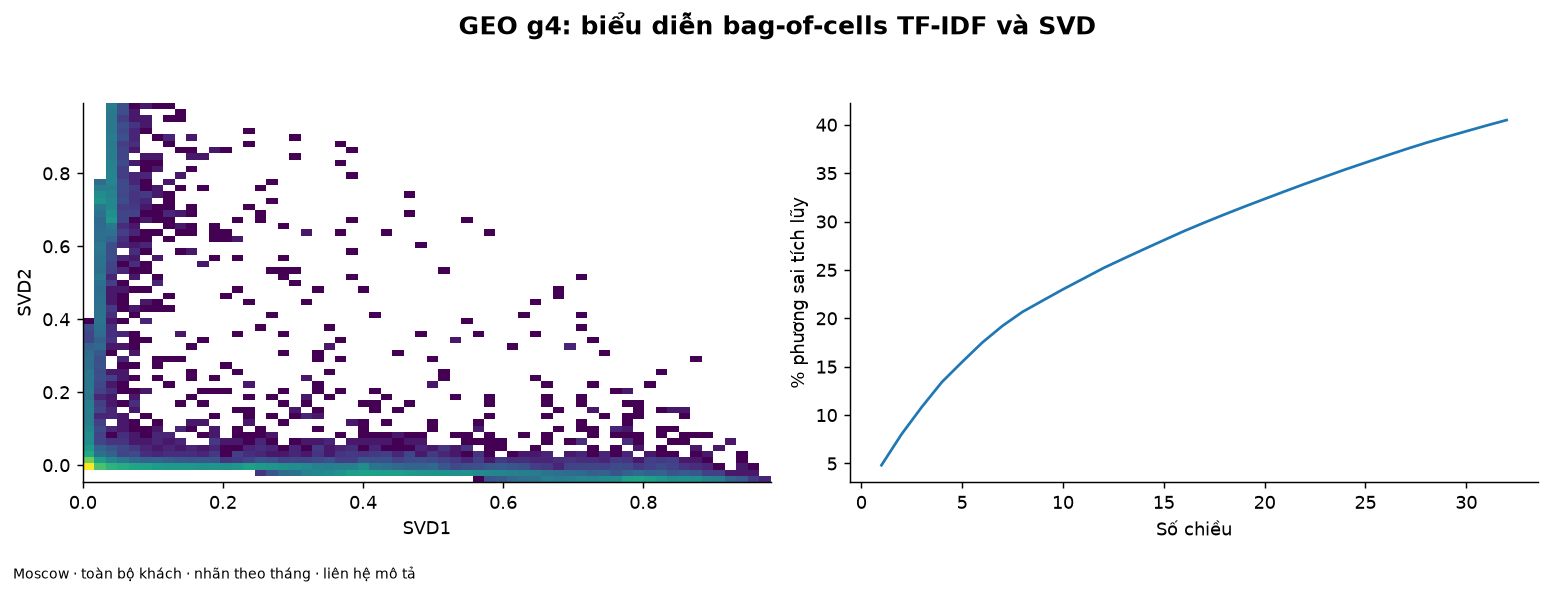

**outputs/eda_figures_moscow/geo_g4_idf_graph.png**

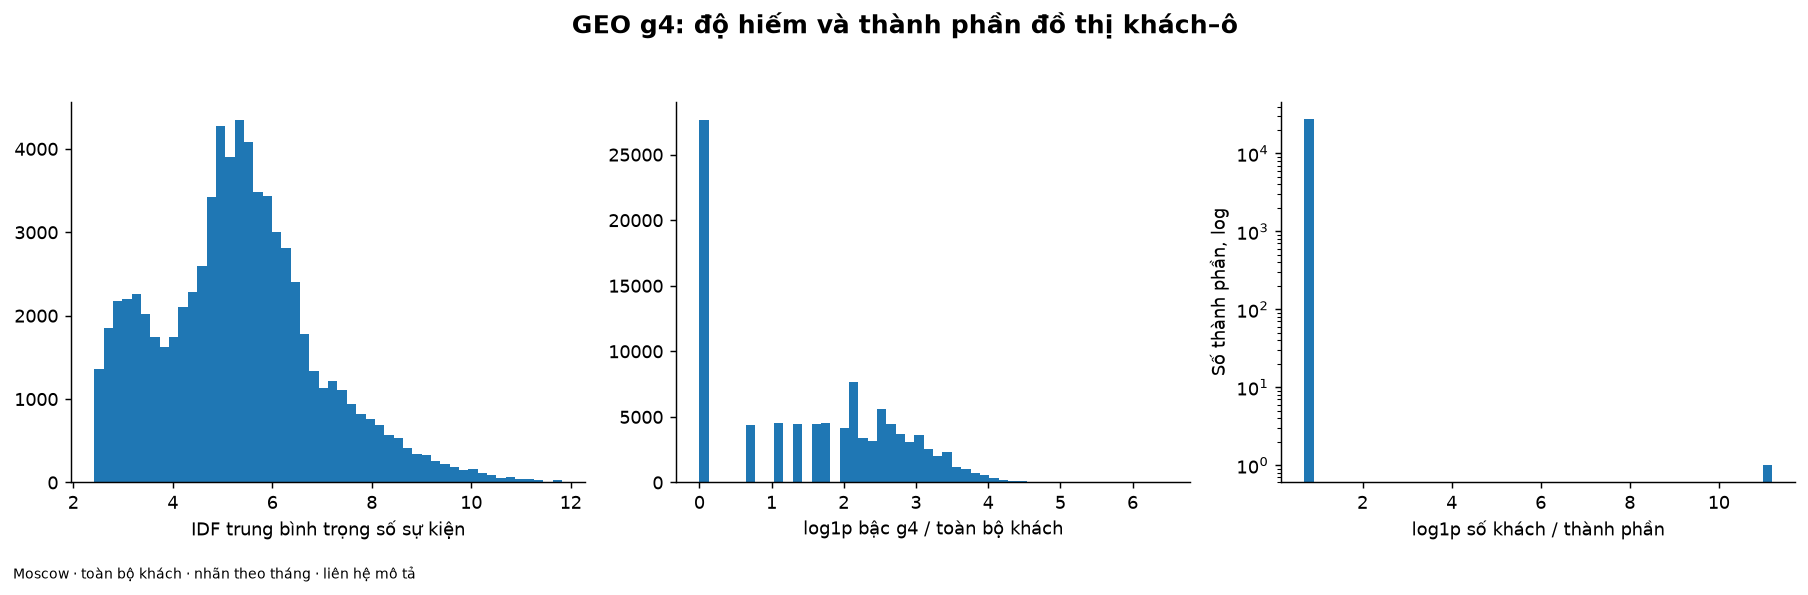

**outputs/eda_figures_moscow/figure_index.csv** — 5 dòng đầu

,figure,title,data,explanation
0,all_history_recency_by_purchase_month,Recency toàn lịch sử trước đầu tháng mua,all_history_recency_by_purchase_month.csv,all_history_recency_by_purchase_month.md
1,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
2,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
3,baseline_event_type_new_cells,event_type_new_cells: thay đổi so với nền của ...,baseline_event_type_new_cells.csv,baseline_event_type_new_cells.md
4,baseline_event_type_unique_cells,event_type_unique_cells: thay đổi so với nền c...,baseline_event_type_unique_cells.csv,baseline_event_type_unique_cells.md


**outputs/eda_figures_moscow/geo_concentration_all_levels.csv** — 5 dòng đầu

,level,customers,median_cells,median_entropy,median_hhi,median_topshare,no_geo_customers
0,4,72573,9.0,0.879355,0.561814,0.727273,27651
1,5,72573,23.0,1.732856,0.293816,0.463758,27651
2,6,72573,57.0,2.672608,0.155216,0.320000,27651


**outputs/eda_figures_moscow/geo_g4_bag_svd.csv** — 5 dòng đầu

,dimension,variance_ratio
0,1,0.048227
1,2,0.032148
2,3,0.028022
3,4,0.025810
4,5,0.020701


**outputs/eda_figures_moscow/geo_g4_idf_graph.csv** — 5 dòng đầu

,component,nodes,customers
0,0,91499,72562
1,1,1,1
2,2,1,1
3,3,1,1
4,4,1,1


File kết quả khác: `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/geo_all_history_customer_profiles.parquet`, `outputs/eda_figures_moscow/geo_concentration_all_levels.md`, `outputs/eda_figures_moscow/geo_g4_bag_svd.md`, `outputs/eda_figures_moscow/geo_g4_bag_svd32.npz`, `outputs/eda_figures_moscow/geo_g4_graph_idf_customers.parquet`, `outputs/eda_figures_moscow/geo_g4_idf_graph.md`

In [10]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_geo_population.py')

## Report Geo Spatial Purchase Moscow

Nguồn: `src/scripts/report_geo_spatial_purchase_moscow.py`. Chạy các ô của phần này theo thứ tự.

In [11]:
__file__ = str(ROOT / 'src/scripts/report_geo_spatial_purchase_moscow.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [12]:
"""Render the human-readable report from the completed Moscow association audit."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

OUT=Path('outputs/geo_spatial_purchase_moscow_20261117')


def main():
    d=pd.read_parquet(OUT/'customer_snapshot.parquet')
    s=pd.read_csv(OUT/'geo_direct_standardization.csv')
    support=pd.read_csv(OUT/'visitor_cell_support.csv').query('horizon==3')
    tests=pd.read_csv(OUT/'global_cell_permutation_all_definitions.csv')
    visitor=tests[tests.condition=='within_trx_strata_all_visitors']
    cell=pd.read_parquet(OUT/'visitor_hierarchical_cell_rates.parquet',filters=[('horizon','=',3),('strength','=',100),('level','in',['g4','g5'])])
    fig,axes=plt.subplots(1,2,figsize=(14,6),dpi=170)
    for ax,level in zip(axes,['g4','g5']):
        z=cell[(cell.level==level)&cell.n.ge(100)].nlargest(12,'n').sort_values('n')
        yy=np.arange(len(z))
        ax.errorbar(z.rate,yy,xerr=np.vstack([np.maximum(0,z.rate-z.wilson_low),np.maximum(0,z.wilson_high-z.rate)]),fmt='o',color='#8293a8',label='Raw rate + 95% Wilson')
        ax.scatter(z.smoothed,yy,marker='D',s=24,color='#208575',label='Hierarchical shrinkage m=100',zorder=3)
        ax.axvline(d.y_3.mean(),color='grey',ls='--',lw=1,label='All-customer baseline')
        ax.set_yticks(yy,[f'{int(r.cell)} (n={int(r.n):,})' for r in z.itertuples()])
        ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_title(f'{level}: 12 most-visited cells')
        ax.set_xlabel('3-month cumulative purchase rate');ax.grid(axis='x',alpha=.2);ax.legend(fontsize=8)
    fig.suptitle('Cell purchase rates among unique visitors | 01 Nov 2022 Moscow cutoff',fontsize=15)
    fig.tight_layout(rect=(0,.05,1,.94))
    fig.text(.02,.015,'A customer may visit multiple cells. Wilson intervals are pointwise. Cells displayed by support, not by purchase rate.',fontsize=10)
    fig.savefig(OUT/'visitor_cell_rates_wilson.png');plt.close(fig)
    lines=['# GEO và tỷ lệ mua — kiểm tra theo giờ Moscow','',
        '**Cutoff:** 01/11/2022 00:00 Europe/Moscow (UTC+3), tương đương 31/10/2022 21:00 UTC.',
        f'**Cohort:** {len(d):,} khách duy nhất; {int(d.has_geo.sum()):,} khách đã có GEO trước cutoff. Mỗi khách chỉ xuất hiện một lần.',
        '**Lịch sử:** toàn bộ lịch sử có sẵn của từng nguồn trước cutoff, không giới hạn 7/30/90 ngày. Không dùng cache đặc trưng UTC cũ.',
        '**Nhãn:** OR của bốn sản phẩm trong tháng 11/2022; tháng 11–12/2022; tháng 11/2022–01/2023, lần lượt cho H=1/2/3.',
        '**Giả định nguồn:** timestamp không timezone của raw tiếp tục được hiểu là UTC như quy ước chuẩn hóa trước đây. Giờ Moscow xác định cutoff và ngày hoạt động; đây không phải xác minh timezone ETL gốc.','',
        '## 1. Tỷ lệ mua theo ô và khoảng tin cậy','',
        'Có hai bảng khác nhau: (a) mọi ô từng ghé, đếm khách riêng biệt trong từng ô; (b) ô chính theo nhánh g4 → g5 → g6, mỗi khách được gán một ô ở mỗi cấp. Bảng mọi ô là kết quả chính cho câu hỏi vị trí đã ghé. Không cộng số khách/người mua giữa các ô vì có giao nhau.','',
        '| Cấp, mọi ô từng ghé | Số ô | Trung vị khách/ô | Ô có ≥100 khách | Ô có <10 khách |',
        '|---|---:|---:|---:|---:|']
    for r in support.itertuples():lines.append(f'| {r.level} | {r.cells:,} | {r.median_n:g} | {r.cells_n_ge100:,} | {r.cells_n_lt10:,} |')
    lines += ['', 'Ngưỡng n≥100 là tiêu chí hiển thị mô tả, không bảo đảm đủ lực kiểm định. Toàn bộ ô vẫn được xuất; CI 95% Wilson là khoảng tin cậy từng ô, không điều chỉnh đồng thời cho hàng nghìn ô. Ô hiển thị trên hình được chọn theo số khách, không chọn theo tỷ lệ mua cao.', '',
        '![Tỷ lệ mua theo mọi ô từng ghé](visitor_cell_rates_wilson.png)','',
        '## 2. Làm trơn phân cấp','',
        '`p_smoothed = (buyers + m × p_parent_smoothed) / (n + m)`; g6 co về g5, g5 co về g4, g4 co về tỷ lệ mua chung của toàn cohort, độc lập cho từng horizon.',
        'Xuất m=20,100,500 để xem độ nhạy; hình dùng m=100. Đây là làm trơn giả đếm phân cấp theo tham số định trước, chưa phải empirical Bayes ước lượng từ dữ liệu. Tỷ lệ cha chứa cả khách của ô con; đây là ước lượng mô tả dạng plug-in, không phải posterior đầy đủ. Wilson chỉ áp dụng cho tỷ lệ thô; không gắn Wilson thô vào ước lượng đã co.',
        'Xuất cả định nghĩa mọi ô từng ghé và ô chính. Ước lượng này dùng nhãn của kỳ phân tích để mô tả; không đưa trực tiếp vào mô hình dự báo cùng kỳ. Target encoding cần fit bằng nhãn quá khứ đã sẵn có và đánh giá ngoài thời gian.','',
        '## 3. Khác biệt giữa các ô có vượt nhiễu mẫu không?','',
        'Dùng tổng bình phương sai lệch số người mua quan sát so với kỳ vọng, chuẩn hóa theo phương sai từng ô. Phân phối tham chiếu lấy bằng hoán vị, không dùng xấp xỉ chi-square cho ô rất thưa.',
        'Đối với mọi ô từng ghé: 499 hoán vị nhãn khách trong từng tầng TRX của nhóm có GEO; mọi cạnh của cùng khách luôn mang cùng nhãn hoán vị. Do đó giữ được việc một khách ghé nhiều ô. Đối với ô chính: 999 hoán vị, thêm đối chiếu hoán vị không phân tầng. Hiệu chỉnh Holm chung cho 18 kiểm định toàn cục.', '',
        '| Horizon | p hoán vị g4, mọi ô | p hoán vị g5, mọi ô |', '|---|---:|---:|']
    for h in [1,2,3]:
        z=visitor[visitor.horizon==h].set_index('level')
        lines.append(f'| {h} tháng | {z.loc["g4","permutation_p"]:.3f} | {z.loc["g5","permutation_p"]:.3f} |')
    lines += ['',f'Khoảng p sau Holm (mọi ô): {visitor.holm_p.min():.3f}–{visitor.holm_p.max():.3f}. Không bác bỏ giả thuyết không chỉ có nghĩa là chưa có bằng chứng khác biệt theo thiết kế này; không chứng minh mọi ô có cùng tỷ lệ mua. Phân tầng TRX còn thô; không kiểm soát mọi yếu tố nhiễu.','',
        '## 4. Có GEO sau phân tầng TRX','',
        'T0: không có bản ghi TRX quan sát trước cutoff (không đồng nghĩa khách thực sự không giao dịch). T1–T5: quintile số sự kiện TRX dương trên toàn lịch sử. Giữ các giá trị bằng nhau trong cùng tầng. Chuẩn hóa trực tiếp hai nhóm GEO về cùng phân bố sáu tầng của toàn cohort.', '',
        '| Horizon | Nền toàn cohort | RR có/không GEO thô | RR chuẩn hóa TRX | CI 95% RR chuẩn hóa |', '|---|---:|---:|---:|---|']
    for r in s.itertuples():
        lines.append(f'| {r.horizon} tháng | {d[f"y_{r.horizon}"].mean():.2%} | {r.crude_rr:.3f} | {r.standardized_rr:.3f} | {r.standardized_rr_low:.3f}–{r.standardized_rr_high:.3f} |')
    lines += ['', 'RR ở đây là tỷ số tỷ lệ mua của nhóm có GEO so với không GEO, khác với lift so với nền toàn cohort. CI của RR chuẩn hóa dùng xấp xỉ delta trên log RR với trọng số tầng cố định; không phải Wilson. Tất cả sáu tầng đều có cả hai nhóm nên giữ 100% trọng số cohort.',
        'Chênh lệch giảm sau điều chỉnh nhưng còn tồn tại. Đây là liên hệ quan sát, chưa phải tác động nhân quả của GEO.', '',
        '![Có GEO trong từng tầng TRX](has_geo_stratified.png)','',
        '## 5. Lift của nhóm chỉ báo trong tầng TRX','',
        'Ba chỉ báo: số sự kiện GEO toàn lịch sử, số ô g4 khác nhau, tỷ lệ sự kiện tại ô g4 chính. Trong mỗi tầng TRX, chia quartile chỉ trên khách có GEO; giữ ties và bỏ ranh giới trùng. Q1–Q4 vì vậy có ngưỡng khác nhau giữa các tầng. Nhóm không GEO giữ riêng.',
        'Lift chính = tỷ lệ mua của quartile / tỷ lệ mua của tất cả khách có GEO trong cùng tầng TRX. CSV còn có lift so với toàn bộ khách trong tầng, số khách, số người mua và Wilson 95%.','',
        'Ở H=3, Q4 số sự kiện GEO có tỷ lệ mua cao hơn Q1 trong cả T1–T5; Q4 số ô g4 cũng cao hơn Q1 trong cả T1–T5. Tỷ lệ ô chính không có chiều nhất quán (Q4 cao hơn Q1 ở 1/5 tầng TRX dương). Đây là so sánh mô tả nhiều nhóm, chưa phải kết luận ý nghĩa thống kê từng ô heatmap. Không chọn nhóm/horizon chỉ dựa trên hình.', '',
        '![Lift từng nhóm chỉ báo](feature_lift_stratified.png)','',
        '## Giới hạn và kiểm chứng','',
        '- Một cutoff duy nhất; chưa chứng minh ổn định qua nhiều kỳ hoặc cải thiện dự báo ngoài thời gian.',
        '- Nguồn GEO và TRX có ngày bắt đầu khác nhau; phân tầng số log chưa kiểm soát độ dài lịch sử/tuổi quan hệ ngân hàng, thiếu dữ liệu và các yếu tố khách hàng khác.',
        '- Ô là mã ẩn danh; không diễn giải thành địa điểm thật, vùng trung tâm hay thu nhập.',
        '- Tổng GEO/TRX trước cutoff đối chiếu trực tiếp raw: 55.335.697 / 35.288.744. Kiểm tra cohort duy nhất, nhãn tích lũy, số khách/người mua, Wilson, co giữa tỷ lệ thô và cha, và phân hoạch tầng đều đạt.',
        '- Không huấn luyện mô hình, không chọn horizon, không báo top-K từ bảng tỷ lệ dùng cùng nhãn.', '',
        '## Tệp kết quả','',
        '- `visitor_g4_g5_wilson.csv`: tỷ lệ mua mọi ô g4/g5 và CI, đủ H=1/2/3.',
        '- `visitor_hierarchical_cell_rates.parquet`: tỷ lệ thô và làm trơn g4/g5/g6, m=20/100/500.',
        '- `global_cell_permutation_all_definitions.csv`: kiểm định mọi ô/ô chính, p Holm chung.',
        '- `geo_direct_standardization.csv`, `has_geo_by_trx_stratum.csv`: RR và tỷ lệ mua phân tầng.',
        '- `feature_lift_by_trx_stratum.csv`: lift nhóm chỉ báo, đủ H=1/2/3.',
        '- `edges_*.csv`, `trx_stratum_edges.csv`: ngưỡng chia tầng và nhóm.',
        '- `customer_snapshot.parquet`, `visitor_memberships.parquet`: snapshot và quan hệ khách–ô đã kiểm soát cutoff.',
        '- `manifest.json`, `validation.json`: giả định, quy trình và kiểm tra.', '',
        'Tái lập theo thứ tự: `src/scripts/analyze_geo_spatial_purchase_moscow.py`, `src/scripts/analyze_geo_visitor_cell_rates.py`, `src/scripts/report_geo_spatial_purchase_moscow.py` với Python trong `.venv`.', '',
        'Phương pháp tham khảo: [Wilson trong statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html); [nguyên tắc kiểm định hoán vị và p Monte Carlo](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).']
    (OUT/'REPORT.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
    manifest=json.loads((OUT/'manifest.json').read_text(encoding='utf-8'))
    manifest.update(visitor_definition='Each customer counted once within every historical cell visited; overlapping membership across cells',
        visitor_permutations=499,visitor_shuffle_unit='Customer label; all cell memberships retain same permuted label',
        holm_family_size=18,authoritative_global_test_file='global_cell_permutation_all_definitions.csv',
        standardized_rr_ci='Fixed-weight delta method on log risk ratio; distinct from pointwise Wilson rate CI')
    (OUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    print('REPORT.md and all-visitor forest plot generated')


if __name__=='__main__':main()

REPORT.md and all-visitor forest plot generated


### Kết quả: `src/scripts/report_geo_spatial_purchase_moscow.py`

**outputs/geo_spatial_purchase_moscow_20261117/visitor_cell_rates_wilson.png**

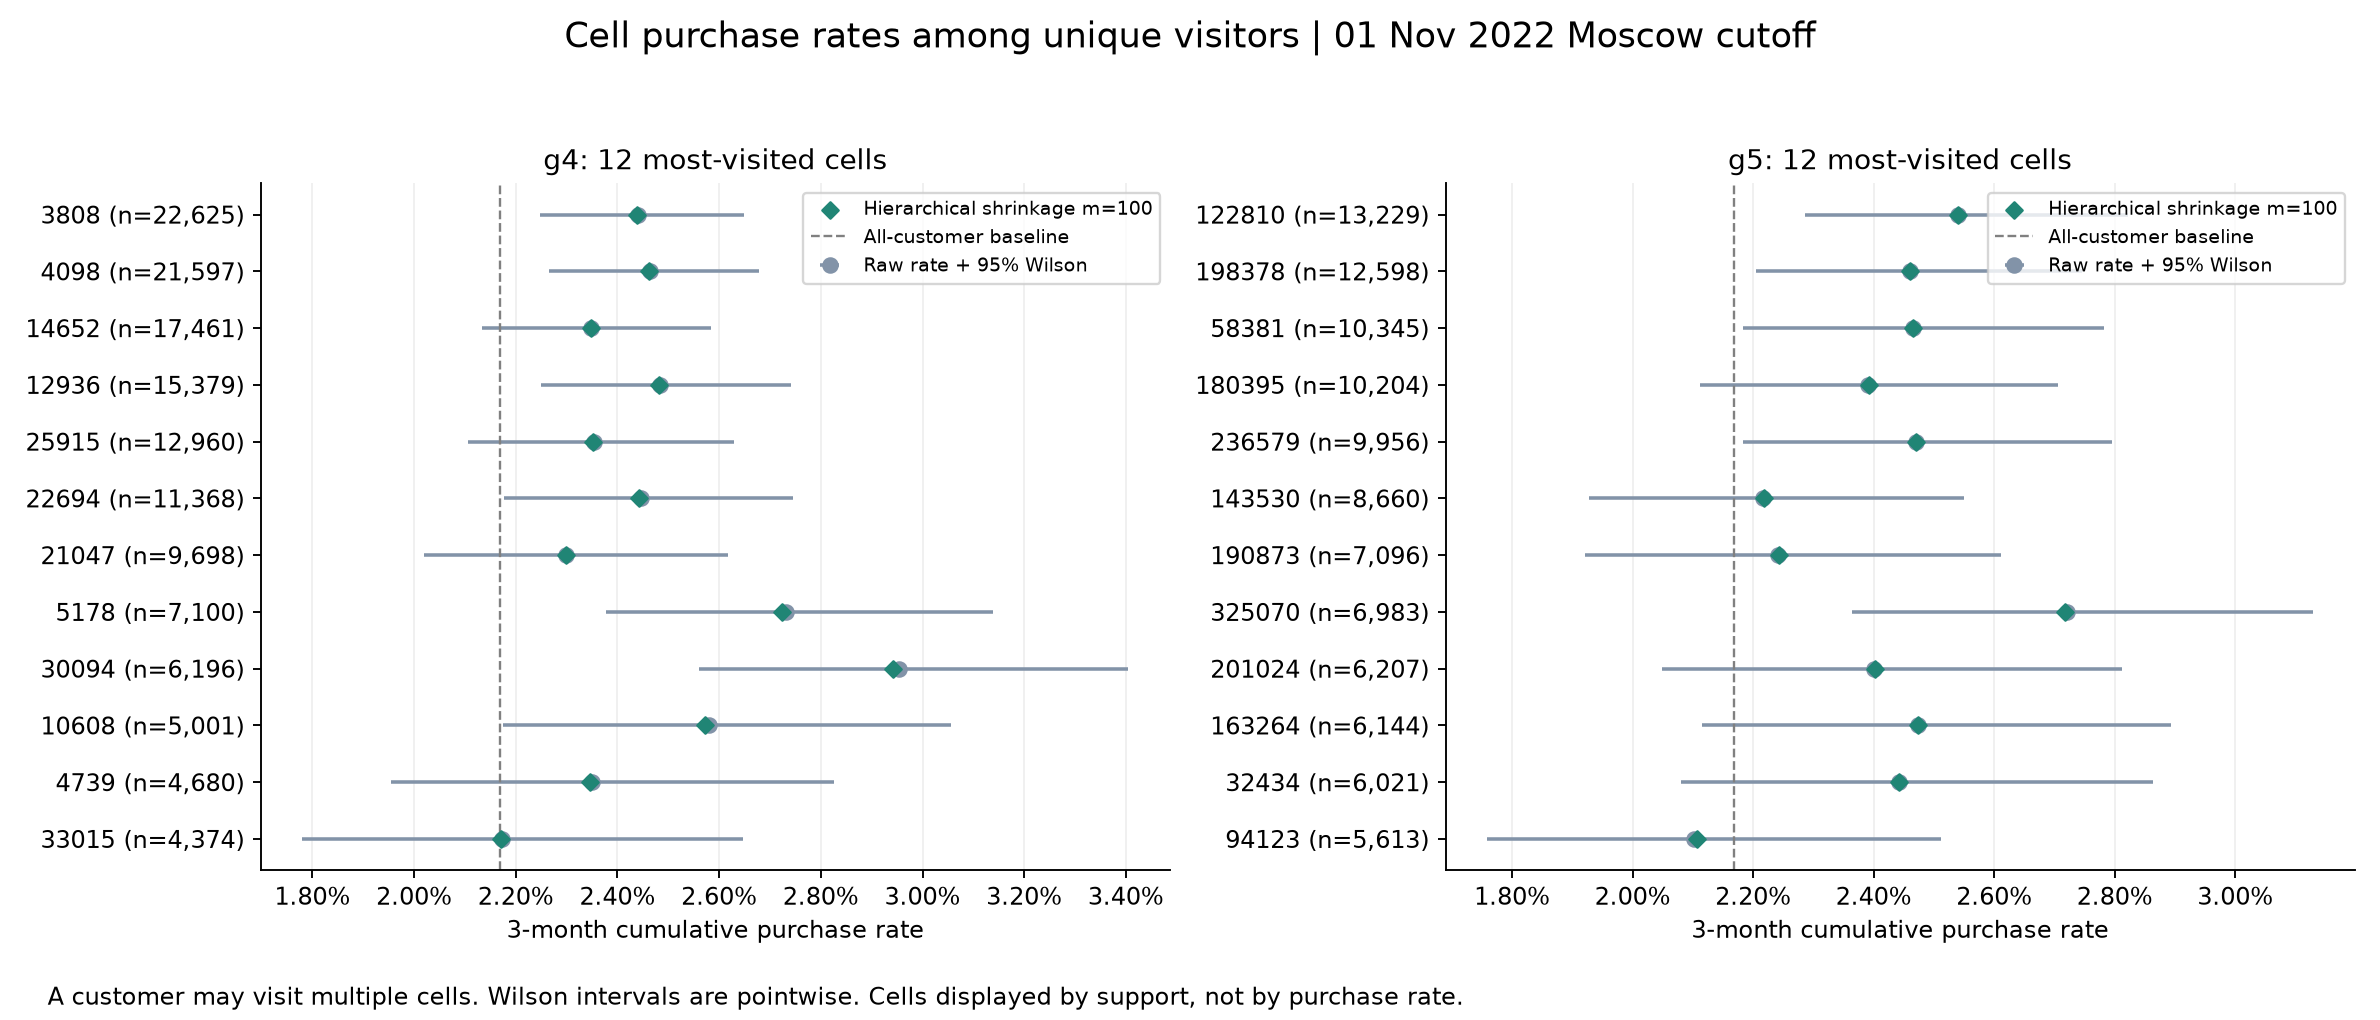

File kết quả khác: `outputs/geo_spatial_purchase_moscow_20261117/REPORT.md`, `outputs/geo_spatial_purchase_moscow_20261117/manifest.json`

In [13]:
show_generated_results(__eda_started_ns, 'src/scripts/report_geo_spatial_purchase_moscow.py')